# Digital Image Processing Lab — Lab Task # 05
## Spatial Filtering and Convolution

| | |
|---|---|
| **Name** | **Sheikh Haseeb-ur-Rehman** |
| **Roll No.** | **2024-SE-31** |
| **Session / Semester** | 2024-28 (SE) / Fifth |
| **Department** | Software Engineering — The University of Azad Jammu and Kashmir |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Assigned / Due** | November 13, 2026 / November 20, 2026, 11:59 PM |

**Contents:** 0 Setup and decisions · 1 Convolution from first principles · 2 Kernels, filters and rules R3/R4 · 3 Dry-run exercises · 4 Noise and reproducibility (R5) · 5 Filtering every noisy image (R1, R2, R6) · 6 Figures · 7 Observations · 8 Viva preparation · 9 Final compliance summary

## 0. Setup and decisions

The lab text leaves a few things open. These are the choices made in this notebook, stated up front so every result below can be checked against them.

1. **Grayscale chelsea.** `camera` and `coins` are already 8-bit grayscale. `chelsea` is RGB, so it is converted with `skimage.color.rgb2gray` (luminance weights) and then rounded to `uint8`. It is *not* contrast-stretched, so it stays a fairly dark image (about 4–193). All three arrays are made read-only so the originals cannot be changed by accident.
2. **`amount` in salt-and-pepper.** `amount=0.05` is the *total* fraction of pixels corrupted: half become 0 (pepper), half become 255 (salt).
3. **Random numbers.** Each noise function builds its own `np.random.default_rng(seed)`. The result therefore does not depend on global state or on the order in which images are processed.
4. **Border handling (R1).** NumPy's `mode="reflect"` mirrors around the edge pixel without repeating it. That is the same as OpenCV's `cv2.BORDER_REFLECT_101`, which is what is used everywhere. One catch: `cv2.medianBlur` has no border option and always *replicates* the edge. To keep R1 true for the median as well, the image is reflect-padded first, `cv2.medianBlur` is run, and the padding is cropped off.
5. **Gaussian kernel.** The weights come from `cv2.getGaussianKernel(k, 0)`, which are the same coefficients `cv2.GaussianBlur(img, (k, k), 0)` uses internally (3×3: 1-2-1 ÷ 16, 5×5: 1-4-6-4-1 ÷ 256 and so on).
6. **True convolution.** `cv2.filter2D` computes *correlation*. When it is used as a reference for `conv2d_loop`, the kernel is flipped first.
7. **"Noisiest image"** is defined objectively as the noisy image with the lowest PSNR against its **clean original** (R6).
8. **Rounding.** `np.rint` (round half to even) followed by `np.clip(0, 255)` and `astype(np.uint8)`, applied only at the end of a calculation (R2).

In [1]:
import hashlib, sys, time
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import skimage
from skimage import data, color
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("OpenCV      :", cv2.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-image:", skimage.__version__)

Python      : 3.14.6
NumPy       : 2.5.4
OpenCV      : 5.0.0
Matplotlib  : 3.11.2
scikit-image: 0.26.0


In [2]:
def sha(a):
    # short fingerprint of an array, used to prove arrays are unchanged / identical
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()[:16]

def to_uint8(a):
    # R2: round, clip to 0-255, convert. Called only at the very end of a calculation.
    return np.clip(np.rint(a), 0, 255).astype(np.uint8)

camera      = data.camera()                                   # already 2-D uint8
coins       = data.coins()                                    # already 2-D uint8
chelsea_rgb = data.chelsea()                                  # RGB uint8
chelsea     = to_uint8(color.rgb2gray(chelsea_rgb) * 255.0)   # grayscale uint8

ORIGINALS = {"camera": camera, "coins": coins, "chelsea": chelsea}
for arr in ORIGINALS.values():
    arr.setflags(write=False)                                 # keep the originals unchanged
ORIG_FINGERPRINT = {name: sha(arr) for name, arr in ORIGINALS.items()}

print(f"{'image':8s} {'shape':12s} {'dtype':6s} {'min':>4s} {'max':>4s}  fingerprint")
for name, arr in ORIGINALS.items():
    print(f"{name:8s} {str(arr.shape):12s} {str(arr.dtype):6s} {arr.min():4d} {arr.max():4d}  {ORIG_FINGERPRINT[name]}")

image    shape        dtype   min  max  fingerprint
camera   (512, 512)   uint8     0  255  5cb24482a53416f9
coins    (303, 384)   uint8     1  252  e080cc03805f1fa7
chelsea  (300, 451)   uint8     4  193  911eff83cc5deec0


## 1. Convolution from first principles

`conv2d_loop(img, kernel)` follows the lab specification step by step:

1. reject kernels with an even side (R4);
2. reflect-pad the image by `kernel//2` on every side, so the output can be the same size (R1);
3. **flip the kernel in both directions**, which turns the sliding-window *correlation* into a true *convolution*;
4. for every pixel `(y, x)`, take the window centred on it and compute the weighted sum in `float64` (R2);
5. return a `float64` array of the same shape as the input. Rounding to `uint8` is left to the caller.

In [3]:
def conv2d_loop(img, kernel):
    # True 2-D convolution with reflect padding. Returns float64, same shape as img (R1, R2).
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if img.ndim != 2 or kernel.ndim != 2:
        raise ValueError("img and kernel must both be 2-D")
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError(f"kernel sides must be odd (R4), got {kernel.shape}")

    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")   # reflect padding
    k_flipped = kernel[::-1, ::-1]                                # flip -> convolution, not correlation
    k_flat = k_flipped.ravel()

    H, W = img.shape
    out = np.empty((H, W), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            window = padded[y:y + kh, x:x + kw]                   # neighbourhood centred on (y, x)
            out[y, x] = np.dot(window.ravel(), k_flat)            # weighted sum, float64
    return out

# tiny sanity check: a "delta" kernel must give back exactly the input
delta = np.zeros((3, 3)); delta[1, 1] = 1.0
small = np.arange(25, dtype=np.float64).reshape(5, 5)
print("delta kernel returns the input unchanged:", np.array_equal(conv2d_loop(small, delta), small))
print("output dtype / shape:", conv2d_loop(small, delta).dtype, conv2d_loop(small, delta).shape)

delta kernel returns the input unchanged: True
output dtype / shape: float64 (5, 5)


### 1.1 Verification against OpenCV on a real image

OpenCV's `cv2.filter2D` performs **correlation**, not convolution. So the reference is `cv2.filter2D` with the kernel **flipped**, using `BORDER_REFLECT_101` (the same border as NumPy's `reflect`).

Mean and Gaussian kernels are symmetric, so for them the flip changes nothing, and they alone could not prove that `conv2d_loop` flips correctly. That is why the first test uses an **asymmetric** kernel (1…9 ÷ 45): it matches OpenCV only if the flip is right, and it clearly disagrees with the un-flipped reference. Then the actual lab kernels (mean, Gaussian) are compared against `cv2.blur` and `cv2.GaussianBlur` on the same image.

In [4]:
def max_abs_diff(a, b):
    return float(np.max(np.abs(np.asarray(a, np.float64) - np.asarray(b, np.float64))))

test = ORIGINALS["camera"]
print("Test image: camera", test.shape, test.dtype, "\n")

# --- (a) asymmetric kernel: proves the flip -------------------------------------------
k_asym = np.arange(1, 10, dtype=np.float64).reshape(3, 3) / 45.0
mine = conv2d_loop(test, k_asym)
cv_flipped   = cv2.filter2D(test, cv2.CV_64F, k_asym[::-1, ::-1], borderType=cv2.BORDER_REFLECT_101)
cv_unflipped = cv2.filter2D(test, cv2.CV_64F, k_asym,             borderType=cv2.BORDER_REFLECT_101)
print("(a) asymmetric 3x3 kernel, float64, no rounding")
print(f"    conv2d_loop vs cv2.filter2D(FLIPPED kernel)   : max |diff| = {max_abs_diff(mine, cv_flipped):.3e}   <- agree")
print(f"    conv2d_loop vs cv2.filter2D(un-flipped kernel): max |diff| = {max_abs_diff(mine, cv_unflipped):.3f}   <- would be wrong: the flip matters\n")

# --- (b) the lab's own kernels, compared after rounding to uint8 -------------------------
mean3_loop = to_uint8(conv2d_loop(test, np.full((3, 3), 1 / 9)))
mean3_cv   = cv2.blur(test, (3, 3), borderType=cv2.BORDER_REFLECT_101)
g = cv2.getGaussianKernel(5, 0).ravel()
gauss5_loop = to_uint8(conv2d_loop(test, np.outer(g, g)))
gauss5_cv   = cv2.GaussianBlur(test, (5, 5), 0, borderType=cv2.BORDER_REFLECT_101)

print("(b) lab kernels after round + clip to uint8 (levels out of 255)")
print(f"    mean 3x3     : conv2d_loop vs cv2.blur         max |diff| = {max_abs_diff(mean3_loop, mean3_cv):.0f}")
print(f"    gaussian 5x5 : conv2d_loop vs cv2.GaussianBlur max |diff| = {max_abs_diff(gauss5_loop, gauss5_cv):.0f}")
print(f"\nLargest difference found overall (uint8 levels): {max(max_abs_diff(mean3_loop, mean3_cv), max_abs_diff(gauss5_loop, gauss5_cv)):.0f}"
      "  -> within rounding, so conv2d_loop is verified.")

Test image: camera (512, 512) uint8 

(a) asymmetric 3x3 kernel, float64, no rounding
    conv2d_loop vs cv2.filter2D(FLIPPED kernel)   : max |diff| = 0.000e+00   <- agree
    conv2d_loop vs cv2.filter2D(un-flipped kernel): max |diff| = 83.289   <- would be wrong: the flip matters

(b) lab kernels after round + clip to uint8 (levels out of 255)
    mean 3x3     : conv2d_loop vs cv2.blur         max |diff| = 0
    gaussian 5x5 : conv2d_loop vs cv2.GaussianBlur max |diff| = 1

Largest difference found overall (uint8 levels): 1  -> within rounding, so conv2d_loop is verified.


## 2. Kernels, filters and the rules R3 / R4

In [5]:
ALLOWED_SIZES = (3, 5, 7)

def check_ksize(k):
    # R4: odd kernel sizes only, and only 3, 5 or 7 for this lab.
    if not isinstance(k, (int, np.integer)) or k % 2 == 0 or k not in ALLOWED_SIZES:
        raise ValueError(f"kernel size must be odd and one of {ALLOWED_SIZES}, got {k!r}")
    return int(k)

def mean_kernel(k):
    k = check_ksize(k)
    return np.full((k, k), 1.0 / k**2)                    # every weight = 1/size^2  -> sums to 1 (R3)

def gaussian_kernel(k):
    k = check_ksize(k)
    g = cv2.getGaussianKernel(k, 0).ravel()               # OpenCV's discrete 1-D Gaussian weights
    return np.outer(g, g)                                 # separable: 2-D kernel = outer product

# ---- R3: print every smoothing kernel's weight sum and confirm it equals 1 ----
print("R3 - weight sums of every smoothing kernel")
for label, make in (("mean    ", mean_kernel), ("gaussian", gaussian_kernel)):
    for k in ALLOWED_SIZES:
        s = make(k).sum()
        assert np.isclose(s, 1.0), f"{label} {k}x{k} does not sum to 1"
        print(f"  {label} {k}x{k}: sum = {s:.15f}  ->  {'OK (= 1)' if np.isclose(s, 1.0) else 'FAIL'}")

print("\nGaussian kernels written as integers over their divisor (the 3x3 one is the 1-2-1 / 16 kernel):")
for k, div in ((3, 16), (5, 256), (7, 16384)):
    ints = np.rint(gaussian_kernel(k) * div).astype(int)
    assert np.allclose(ints / div, gaussian_kernel(k))
    print(f"\n{k}x{k}  (divide by {div}; integer weights add up to {ints.sum()})")
    print(ints)

R3 - weight sums of every smoothing kernel
  mean     3x3: sum = 1.000000000000000  ->  OK (= 1)
  mean     5x5: sum = 1.000000000000000  ->  OK (= 1)
  mean     7x7: sum = 1.000000000000000  ->  OK (= 1)
  gaussian 3x3: sum = 1.000000000000000  ->  OK (= 1)
  gaussian 5x5: sum = 1.000000000000000  ->  OK (= 1)
  gaussian 7x7: sum = 1.000000000000000  ->  OK (= 1)

Gaussian kernels written as integers over their divisor (the 3x3 one is the 1-2-1 / 16 kernel):

3x3  (divide by 16; integer weights add up to 16)
[[1 2 1]
 [2 4 2]
 [1 2 1]]

5x5  (divide by 256; integer weights add up to 256)
[[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]

7x7  (divide by 16384; integer weights add up to 16384)
[[  16   56  112  144  112   56   16]
 [  56  196  392  504  392  196   56]
 [ 112  392  784 1008  784  392  112]
 [ 144  504 1008 1296 1008  504  144]
 [ 112  392  784 1008  784  392  112]
 [  56  196  392  504  392  196   56]
 [  16   56  112  144  112  

In [6]:
# ---- The three filters, all with reflect borders (R1) and uint8 output (R2) ----
def mean_loop(img, k):                  # mean via our own convolution
    return to_uint8(conv2d_loop(img, mean_kernel(k)))

def mean_cv(img, k):                    # mean via OpenCV (fast)
    k = check_ksize(k)
    return cv2.blur(img, (k, k), borderType=cv2.BORDER_REFLECT_101)

def gaussian_cv(img, k):                # Gaussian via OpenCV
    k = check_ksize(k)
    return cv2.GaussianBlur(img, (k, k), 0, borderType=cv2.BORDER_REFLECT_101)

def median_cv(img, k):                  # median via OpenCV, with reflect padding added by us
    k = check_ksize(k)
    p = k // 2
    padded = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REFLECT_101)
    return np.ascontiguousarray(cv2.medianBlur(padded, k)[p:-p, p:-p])

def median_loop(img, k):                # slow reference: middle value of the sorted neighbourhood
    k = check_ksize(k)
    p = k // 2
    padded = np.pad(np.asarray(img, np.float64), p, mode="reflect")
    out = np.empty(img.shape, dtype=np.float64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sort(padded[y:y + k, x:x + k], axis=None)[(k * k) // 2]
    return to_uint8(out)

FILTERS = {"Mean": mean_cv, "Gaussian": gaussian_cv, "Median": median_cv}

# ---- check cv2.medianBlur against the definition, and look at its border behaviour ----
rng_demo = np.random.default_rng(1)
crop = rng_demo.integers(0, 256, (40, 40), dtype=np.uint8)           # small random patch
print("median: OpenCV vs the definition (sorted neighbourhood) on a 40x40 patch")
for k in ALLOWED_SIZES:
    p = k // 2
    ours    = median_loop(crop, k)
    wrapped = median_cv(crop, k)                                      # reflect-padded cv2.medianBlur
    raw     = cv2.medianBlur(crop, k)                                 # cv2.medianBlur used directly
    border  = np.ones(crop.shape, bool); border[p:-p, p:-p] = False
    print(f"  {k}x{k}: reflect-padded medianBlur == definition everywhere: {np.array_equal(ours, wrapped)} | "
          f"raw medianBlur differs in {int((raw != ours).sum())} pixels, all on the border: {not (raw != ours)[~border].any()}")

median: OpenCV vs the definition (sorted neighbourhood) on a 40x40 patch
  3x3: reflect-padded medianBlur == definition everywhere: True | raw medianBlur differs in 155 pixels, all on the border: True
  5x5: reflect-padded medianBlur == definition everywhere: True | raw medianBlur differs in 227 pixels, all on the border: True
  7x7: reflect-padded medianBlur == definition everywhere: True | raw medianBlur differs in 368 pixels, all on the border: True


### 2.1 R4 — an even kernel size must be rejected

OpenCV refuses an even median size with an assertion error. The helper functions written above and `conv2d_loop` refuse it as well, so no filter in this notebook can silently run with an even kernel.

In [7]:
img = ORIGINALS["camera"]

print("R4 - cv2.medianBlur(img, 4):")
try:
    cv2.medianBlur(img, 4)
    print("  no error raised (unexpected)")
except cv2.error as e:
    print("  cv2.error raised ->", str(e).splitlines()[0].split("error:")[-1].strip())

print("\nOur own wrappers and conv2d_loop:")
for label, call in (("mean_cv(img, 4)    ", lambda: mean_cv(img, 4)),
                    ("gaussian_cv(img, 6)", lambda: gaussian_cv(img, 6)),
                    ("median_cv(img, 2)  ", lambda: median_cv(img, 2)),
                    ("median_cv(img, 9)  ", lambda: median_cv(img, 9)),
                    ("conv2d_loop(4x4)   ", lambda: conv2d_loop(img[:8, :8], np.ones((4, 4)) / 16))):
    try:
        call()
        print(f"  {label} -> accepted (unexpected)")
    except ValueError as e:
        print(f"  {label} -> ValueError: {e}")
print("\n(9 is odd but outside the lab's 3/5/7 set, so it is rejected too.)")

R4 - cv2.medianBlur(img, 4):
  cv2.error raised -> (-215:Assertion failed) (ksize % 2 == 1) && (_src0.dims() <= 2 ) in function 'cv::medianBlur'

Our own wrappers and conv2d_loop:
  mean_cv(img, 4)     -> ValueError: kernel size must be odd and one of (3, 5, 7), got 4
  gaussian_cv(img, 6) -> ValueError: kernel size must be odd and one of (3, 5, 7), got 6
  median_cv(img, 2)   -> ValueError: kernel size must be odd and one of (3, 5, 7), got 2
  median_cv(img, 9)   -> ValueError: kernel size must be odd and one of (3, 5, 7), got 9
  conv2d_loop(4x4)    -> ValueError: kernel sides must be odd (R4), got (4, 4)

(9 is odd but outside the lab's 3/5/7 set, so it is rejected too.)


## 3. Dry-run exercises

Each hand calculation is typed in the markdown cell, and the code cell directly below it computes the same value so the two can be compared.

### Exercise 1 — Spike response

Neighbourhood (the centre is the bright 255 pixel):

$$
\begin{bmatrix} 40 & 40 & 40 \\ 40 & 255 & 40 \\ 40 & 40 & 40 \end{bmatrix}
$$

**(a) 3×3 mean kernel** (every weight is 1/9)

- Sum of the nine values: 8 × 40 + 255 = 320 + 255 = **575**
- Centre output = 575 ÷ 9 = 63.888… → **64**

**(b) 3×3 Gaussian kernel** $\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$

- Row 1: 1·40 + 2·40 + 1·40 = 160
- Row 2: 2·40 + 4·255 + 2·40 = 80 + 1020 + 80 = 1180
- Row 3: 1·40 + 2·40 + 1·40 = 160
- Weighted sum = 160 + 1180 + 160 = **1500**
- Centre output = 1500 ÷ 16 = 93.75 → **94**

**(c) 3×3 median**

- Sorted values: 40, 40, 40, 40, 40, 40, 40, 40, 255
- The middle (5th of 9) value is **40**

**Reading the result.** The true background is 40. The mean is off by +24, the Gaussian by +54, and the median by 0. The Gaussian does worse than the mean here because it gives the centre pixel a weight of 4/16 = 25 %, against 1/9 ≈ 11 % for the mean, so the spike counts for more.

In [8]:
window = np.array([[40, 40, 40],
                   [40, 255, 40],
                   [40, 40, 40]], dtype=np.uint8)
w16 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])

print("(a) mean     : sum of nine values =", int(window.sum()), "-> /9 =", window.sum() / 9)
print("(b) gaussian : row sums =", (window * w16).sum(axis=1).tolist(),
      "-> weighted sum =", int((window * w16).sum()), "-> /16 =", (window * w16).sum() / 16)
print("(c) median   : sorted =", np.sort(window, axis=None).tolist(), "-> middle value =", int(np.sort(window, axis=None)[4]))

# the notebook's own filters (centre pixel of the 3x3 window)
mean_c  = conv2d_loop(window, mean_kernel(3))[1, 1]
gauss_c = conv2d_loop(window, gaussian_kernel(3))[1, 1]
med_c   = median_cv(window, 3)[1, 1]
print("\nconv2d_loop mean     :", mean_c,  "->", int(to_uint8(mean_c)),  "| cv2.blur         :", int(mean_cv(window, 3)[1, 1]))
print("conv2d_loop gaussian :", gauss_c, "->", int(to_uint8(gauss_c)), "| cv2.GaussianBlur :", int(gaussian_cv(window, 3)[1, 1]))
print("median_cv (cv2.medianBlur):", int(med_c))

assert np.isclose(mean_c, 575 / 9) and int(to_uint8(mean_c)) == 64
assert np.isclose(gauss_c, 1500 / 16) and int(to_uint8(gauss_c)) == 94
assert int(med_c) == 40
print("\nHand calculations and code agree: mean = 64, Gaussian = 94, median = 40")

(a) mean     : sum of nine values = 575 -> /9 = 63.888888888888886
(b) gaussian : row sums = [160, 1180, 160] -> weighted sum = 1500 -> /16 = 93.75
(c) median   : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255] -> middle value = 40

conv2d_loop mean     : 63.888888888888886 -> 64 | cv2.blur         : 64
conv2d_loop gaussian : 93.75 -> 94 | cv2.GaussianBlur : 94
median_cv (cv2.medianBlur): 40

Hand calculations and code agree: mean = 64, Gaussian = 94, median = 40


### Exercise 2 — Reflect padding at a corner

$$
I = \begin{bmatrix} 10 & 20 & 30 \\ 40 & 50 & 60 \\ 70 & 80 & 90 \end{bmatrix}
$$

NumPy's `mode="reflect"` mirrors the image **around the edge pixel without repeating it**. The pixel above row 0 is therefore row 1, and the pixel to the left of column 0 is column 1. The 3×3 neighbourhood of pixel (0, 0) is made of rows (1, 0, 1) and columns (1, 0, 1):

$$
\begin{bmatrix} 50 & 40 & 50 \\ 20 & 10 & 20 \\ 50 & 40 & 50 \end{bmatrix}
$$

- Row 1: 50 + 40 + 50 = 140
- Row 2: 20 + 10 + 20 = 50
- Row 3: 50 + 40 + 50 = 140
- Sum = **330**
- Mean = 330 ÷ 9 = 36.666… → **37**

In [9]:
img3 = np.array([[10, 20, 30],
                 [40, 50, 60],
                 [70, 80, 90]], dtype=np.uint8)

padded = np.pad(img3, 1, mode="reflect")
print("reflect-padded image (5x5):")
print(padded)

nbhd = padded[0:3, 0:3]                         # neighbourhood of pixel (0, 0)
print("\nneighbourhood of (0, 0):")
print(nbhd)
print("row sums:", nbhd.sum(axis=1).tolist(), "| total =", int(nbhd.sum()), "| mean =", nbhd.sum() / 9, "->", int(to_uint8(nbhd.sum() / 9)))

loop_val = conv2d_loop(img3, mean_kernel(3))[0, 0]
cv_val   = cv2.blur(img3, (3, 3), borderType=cv2.BORDER_REFLECT_101)[0, 0]
print("\nconv2d_loop mean at (0, 0):", loop_val, "->", int(to_uint8(loop_val)), "| cv2.blur at (0, 0):", int(cv_val))
assert np.isclose(loop_val, 330 / 9) and int(to_uint8(loop_val)) == 37 and int(cv_val) == 37
print("Hand calculation and code agree: 37")

# why the padding mode matters (same 3x3 mean at the same pixel)
print("\nSame pixel, other padding modes (for contrast):")
for mode in ("constant", "edge", "symmetric"):
    pm = np.pad(img3, 1, mode=mode)[0:3, 0:3]
    print(f"  {mode:9s}: mean = {pm.sum() / 9:.2f}")
print(f"  {'reflect':9s}: mean = {nbhd.sum() / 9:.2f}   <- the one the lab requires (R1)")

reflect-padded image (5x5):
[[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood of (0, 0):
[[50 40 50]
 [20 10 20]
 [50 40 50]]
row sums: [140, 50, 140] | total = 330 | mean = 36.666666666666664 -> 37

conv2d_loop mean at (0, 0): 36.666666666666664 -> 37 | cv2.blur at (0, 0): 37
Hand calculation and code agree: 37

Same pixel, other padding modes (for contrast):
  constant : mean = 13.33
  edge     : mean = 23.33
  symmetric: mean = 23.33
  reflect  : mean = 36.67   <- the one the lab requires (R1)


## 4. Noise generation and reproducibility (R5)

Both noise functions are written from scratch and take their random numbers from `np.random.default_rng(seed)`, created *inside* the function.

- **Gaussian noise:** add N(0, σ²) noise in `float64`, then round, clip and convert once at the end (R2).
- **Salt-and-pepper:** draw one uniform number per pixel. Below `amount/2` the pixel becomes 0 (pepper). Between `amount/2` and `amount` it becomes 255 (salt). So `amount` is the total corrupted fraction.

In [10]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, img.shape)   # float64 arithmetic (R2)
    return to_uint8(noisy)                                              # round + clip once, at the end

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    out = img.copy()
    u = rng.random(img.shape)
    out[u < amount / 2] = 0                                             # pepper
    out[(u >= amount / 2) & (u < amount)] = 255                        # salt
    return out

def build_noisy():
    noisy = {}
    for name, im in ORIGINALS.items():
        noisy[(name, "gaussian")]   = add_gaussian_noise(im, sigma=20, seed=5)
        noisy[(name, "saltpepper")] = add_salt_pepper(im, amount=0.05, seed=5)
    return noisy

NOISY = build_noisy()
print("noisy images generated:", len(NOISY), "(3 images x 2 noise types)")
print("originals unchanged by the noise functions:",
      all(sha(ORIGINALS[n]) == ORIG_FINGERPRINT[n] for n in ORIGINALS))

noisy images generated: 6 (3 images x 2 noise types)
originals unchanged by the noise functions: True


In [11]:
# ---- R5: regenerate with seed=5 and confirm the images are identical ----
np.random.seed(999); _ = np.random.rand(1000)           # disturb NumPy's global RNG on purpose
regen = {}
for name in reversed(list(ORIGINALS)):                  # different processing order, too
    regen[(name, "saltpepper")] = add_salt_pepper(ORIGINALS[name], amount=0.05, seed=5)
    regen[(name, "gaussian")]   = add_gaussian_noise(ORIGINALS[name], sigma=20, seed=5)

print("R5 - regenerated with seed=5 and compared with the first generation")
for key in NOISY:
    same = np.array_equal(NOISY[key], regen[key])
    assert same
    print(f"  {key[0]:8s} {key[1]:11s} np.array_equal = {same}   sha256[:16] = {sha(NOISY[key])}")

# sanity check: the seed really is what controls the noise
other = add_gaussian_noise(ORIGINALS["camera"], sigma=20, seed=6)
print("\nseed=6 gives a different image than seed=5:", not np.array_equal(other, NOISY[("camera", "gaussian")]))
print("(Restart the kernel and re-run: the sha256 values above come out the same every time.)")

R5 - regenerated with seed=5 and compared with the first generation
  camera   gaussian    np.array_equal = True   sha256[:16] = e4857555cfa98812
  camera   saltpepper  np.array_equal = True   sha256[:16] = b7acbef15f927642
  coins    gaussian    np.array_equal = True   sha256[:16] = 24184f5e895e2045
  coins    saltpepper  np.array_equal = True   sha256[:16] = 9dde40fc9b496a54
  chelsea  gaussian    np.array_equal = True   sha256[:16] = 55b29d3092863193
  chelsea  saltpepper  np.array_equal = True   sha256[:16] = e5514260317f6c0f

seed=6 gives a different image than seed=5: True
(Restart the kernel and re-run: the sha256 values above come out the same every time.)


### 4.1 Judging against the clean original (R6)

Every score in this notebook comes from `evaluate(name, test)`, which looks up the **clean original by name** and compares `test` with it. There is no way to pass the noisy image as the reference, so R6 cannot be broken by accident. Three numbers are reported: **MSE** (lower is better), **PSNR** in dB (higher is better) and **SSIM** (closer to 1 is better).

In [12]:
def evaluate(name, test):
    # R6: the reference is ALWAYS the clean original of image `name`
    clean = ORIGINALS[name]
    assert test.shape == clean.shape
    mse  = float(np.mean((test.astype(np.float64) - clean.astype(np.float64)) ** 2))
    psnr = float(peak_signal_noise_ratio(clean, test, data_range=255))
    ssim = float(structural_similarity(clean, test, data_range=255))
    return mse, psnr, ssim

NOISE_LABEL = {"gaussian": "Gaussian noise (sigma=20)", "saltpepper": "Salt & pepper (5%)"}

print("Noisy images, scored against their CLEAN originals")
print(f"{'image':8s} {'noise':26s} {'MSE':>9s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
NOISY_SCORE = {}
for key, im in NOISY.items():
    NOISY_SCORE[key] = evaluate(key[0], im)
    m, p, s = NOISY_SCORE[key]
    print(f"{key[0]:8s} {NOISE_LABEL[key[1]]:26s} {m:9.1f} {p:10.2f} {s:7.3f}")

NOISIEST = min(NOISY_SCORE, key=lambda k: NOISY_SCORE[k][1])
print(f"\nNoisiest image (lowest PSNR vs the clean original): {NOISIEST[0]} + {NOISE_LABEL[NOISIEST[1]]}  "
      f"({NOISY_SCORE[NOISIEST][1]:.2f} dB)")

Noisy images, scored against their CLEAN originals
image    noise                            MSE  PSNR (dB)    SSIM
camera   Gaussian noise (sigma=20)      374.1      22.40   0.366
camera   Salt & pepper (5%)            1108.2      17.68   0.354
coins    Gaussian noise (sigma=20)      391.7      22.20   0.455
coins    Salt & pepper (5%)            1009.0      18.09   0.417
chelsea  Gaussian noise (sigma=20)      398.6      22.13   0.390
chelsea  Salt & pepper (5%)             886.9      18.65   0.327

Noisiest image (lowest PSNR vs the clean original): camera + Salt & pepper (5%)  (17.68 dB)


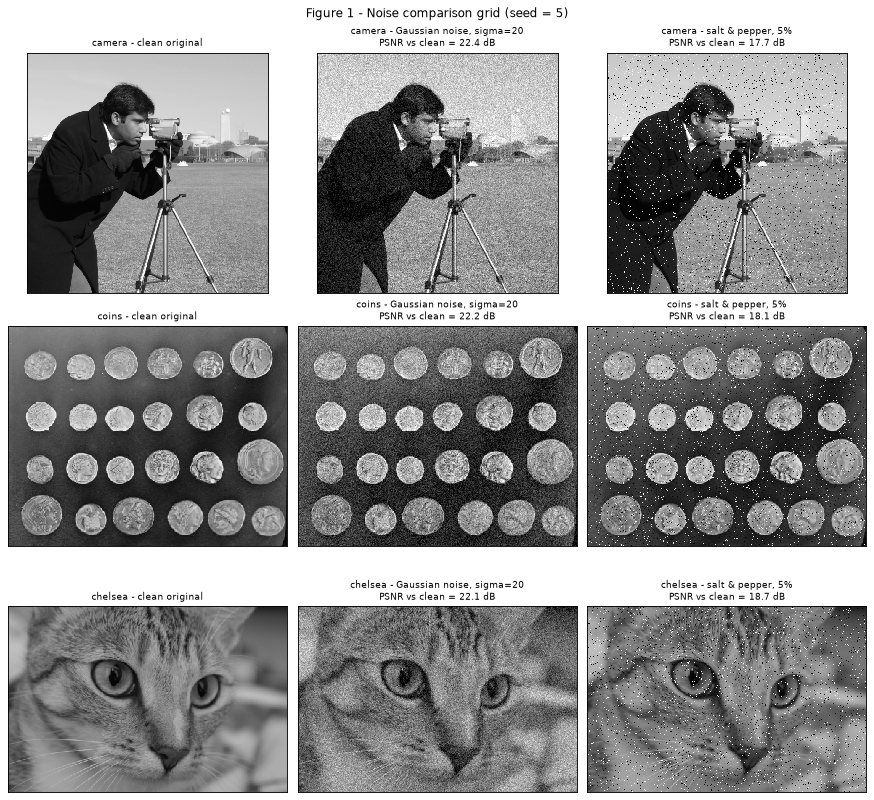

In [13]:
# ---- Figure 1: original | Gaussian noise | salt & pepper, for each test image ----
def show(ax, im, title):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(3, 3, figsize=(11, 10.5))
for r, name in enumerate(ORIGINALS):
    show(axes[r, 0], ORIGINALS[name], f"{name} - clean original")
    show(axes[r, 1], NOISY[(name, "gaussian")],   f"{name} - Gaussian noise, sigma=20\nPSNR vs clean = {NOISY_SCORE[(name, 'gaussian')][1]:.1f} dB")
    show(axes[r, 2], NOISY[(name, "saltpepper")], f"{name} - salt & pepper, 5%\nPSNR vs clean = {NOISY_SCORE[(name, 'saltpepper')][1]:.1f} dB")
fig.suptitle("Figure 1 - Noise comparison grid (seed = 5)", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Filtering every noisy image

Mean, Gaussian and median filters are applied at 3×3, 5×5 and 7×7 to all six noisy images (3 images × 2 noise types), which gives 6 × 3 × 3 = **54 outputs**. The mean filter is additionally run through the notebook's own `conv2d_loop` and compared with `cv2.blur`, as the lab requires.

In [14]:
SIZES = (3, 5, 7)
RESULTS = {}                                    # (image, noise, filter, size) -> uint8 array
for (name, noise), noisy_img in NOISY.items():
    for fname, fn in FILTERS.items():
        for k in SIZES:
            RESULTS[(name, noise, fname, k)] = fn(noisy_img, k)
print("filtered outputs:", len(RESULTS))

# mean filter: conv2d_loop (our own) vs cv2.blur, every noisy image and every size
t0 = time.time()
print("\nMean filter - conv2d_loop vs cv2.blur (max |difference| in uint8 levels)")
print(f"{'image':8s} {'noise':11s} {'3x3':>5s} {'5x5':>5s} {'7x7':>5s}")
worst = 0
for (name, noise), noisy_img in NOISY.items():
    diffs = []
    for k in SIZES:
        d = int(np.max(np.abs(mean_loop(noisy_img, k).astype(int) - RESULTS[(name, noise, "Mean", k)].astype(int))))
        diffs.append(d); worst = max(worst, d)
    print(f"{name:8s} {noise:11s} {diffs[0]:5d} {diffs[1]:5d} {diffs[2]:5d}")
print(f"\nLargest disagreement over all 18 comparisons: {worst} level(s) of 255 -> agree within rounding"
      f"   ({time.time() - t0:.0f} s for the slow loops)")

filtered outputs: 54

Mean filter - conv2d_loop vs cv2.blur (max |difference| in uint8 levels)
image    noise         3x3   5x5   7x7
camera   gaussian        0     0     0
camera   saltpepper      0     0     0
coins    gaussian        0     0     0
coins    saltpepper      0     0     0
chelsea  gaussian        0     0     0
chelsea  saltpepper      0     0     0

Largest disagreement over all 18 comparisons: 0 level(s) of 255 -> agree within rounding   (12 s for the slow loops)


In [15]:
# ---- R1 + R2: dtype uint8, values in 0-255, same shape as the input ----
fails = 0
for (name, noise, fname, k), out in RESULTS.items():
    ref = NOISY[(name, noise)]
    ok = (out.dtype == np.uint8) and (int(out.min()) >= 0) and (int(out.max()) <= 255) and (out.shape == ref.shape)
    fails += (not ok)
print(f"R1/R2: {len(RESULTS) - fails} of {len(RESULTS)} filtered outputs are uint8, within 0-255 and the same shape as their input")
assert fails == 0

print("\nExample (camera, Gaussian noise):")
print(f"{'filter':9s} {'size':5s} {'dtype':6s} {'shape':10s} {'min':>4s} {'max':>4s}")
for fname in FILTERS:
    for k in SIZES:
        o = RESULTS[("camera", "gaussian", fname, k)]
        print(f"{fname:9s} {k}x{k}  {str(o.dtype):6s} {str(o.shape):10s} {o.min():4d} {o.max():4d}")

# conv2d_loop returns float64 before the final conversion (R2)
f = conv2d_loop(NOISY[("coins", "gaussian")][:20, :20], mean_kernel(3))
print("\nconv2d_loop output dtype before conversion:", f.dtype, "(float64, as required)")

R1/R2: 54 of 54 filtered outputs are uint8, within 0-255 and the same shape as their input

Example (camera, Gaussian noise):
filter    size  dtype  shape       min  max
Mean      3x3  uint8  (512, 512)    0  254
Mean      5x5  uint8  (512, 512)    1  251
Mean      7x7  uint8  (512, 512)    3  249
Gaussian  3x3  uint8  (512, 512)    0  253
Gaussian  5x5  uint8  (512, 512)    1  252
Gaussian  7x7  uint8  (512, 512)    2  250
Median    3x3  uint8  (512, 512)    0  255
Median    5x5  uint8  (512, 512)    0  255
Median    7x7  uint8  (512, 512)    0  255

conv2d_loop output dtype before conversion: float64 (float64, as required)


In [16]:
# ---- Scores of every filtered image against the clean original (R6) ----
SCORES = {key: evaluate(key[0], out) for key, out in RESULTS.items()}

cols = [(f, k) for f in FILTERS for k in SIZES]
def table(idx, title, fmt):
    print(title)
    print(f"{'image':8s} {'noise':11s} {'noisy':>7s} | " + " ".join(f"{f[:4]}{k}".rjust(7) for f, k in cols))
    for (name, noise) in NOISY:
        row = [fmt(SCORES[(name, noise, f, k)][idx]) for f, k in cols]
        print(f"{name:8s} {noise:11s} {fmt(NOISY_SCORE[(name, noise)][idx]):>7s} | " + " ".join(v.rjust(7) for v in row))
    print()

table(1, "PSNR vs CLEAN original (dB, higher = better)   [Mean3 = mean 3x3, Gaus5 = Gaussian 5x5, Medi7 = median 7x7, ...]", lambda v: f"{v:.2f}")
table(2, "SSIM vs CLEAN original (1 = identical to the clean image)", lambda v: f"{v:.3f}")

print("Average PSNR over the three images, 3x3 filters only (dB):")
for noise in ("gaussian", "saltpepper"):
    base = np.mean([NOISY_SCORE[(n, noise)][1] for n in ORIGINALS])
    line = f"  {NOISE_LABEL[noise]:26s} noisy = {base:5.2f} | " + " | ".join(
        f"{f} = {np.mean([SCORES[(n, noise, f, 3)][1] for n in ORIGINALS]):5.2f}" for f in FILTERS)
    print(line)

PSNR vs CLEAN original (dB, higher = better)   [Mean3 = mean 3x3, Gaus5 = Gaussian 5x5, Medi7 = median 7x7, ...]
image    noise         noisy |   Mean3   Mean5   Mean7   Gaus3   Gaus5   Gaus7   Medi3   Medi5   Medi7
camera   gaussian      22.40 |   27.37   26.17   24.85   27.99   27.81   26.95   26.93   26.83   25.79
camera   saltpepper    17.68 |   24.84   25.09   24.26   24.73   25.66   25.67   30.08   27.85   26.24
coins    gaussian      22.20 |   25.86   24.03   22.78   26.79   26.02   24.87   25.98   25.34   24.48
coins    saltpepper    18.09 |   24.09   23.36   22.38   24.37   24.58   24.04   28.33   26.25   25.17
chelsea  gaussian      22.13 |   29.54   29.54   28.73   29.45   30.36   30.27   28.26   29.08   28.72
chelsea  saltpepper    18.65 |   26.97   28.24   27.97   26.49   28.09   28.76   33.86   30.93   29.66

SSIM vs CLEAN original (1 = identical to the clean image)
image    noise         noisy |   Mean3   Mean5   Mean7   Gaus3   Gaus5   Gaus7   Medi3   Medi5   Medi7
came

## 6. Figures

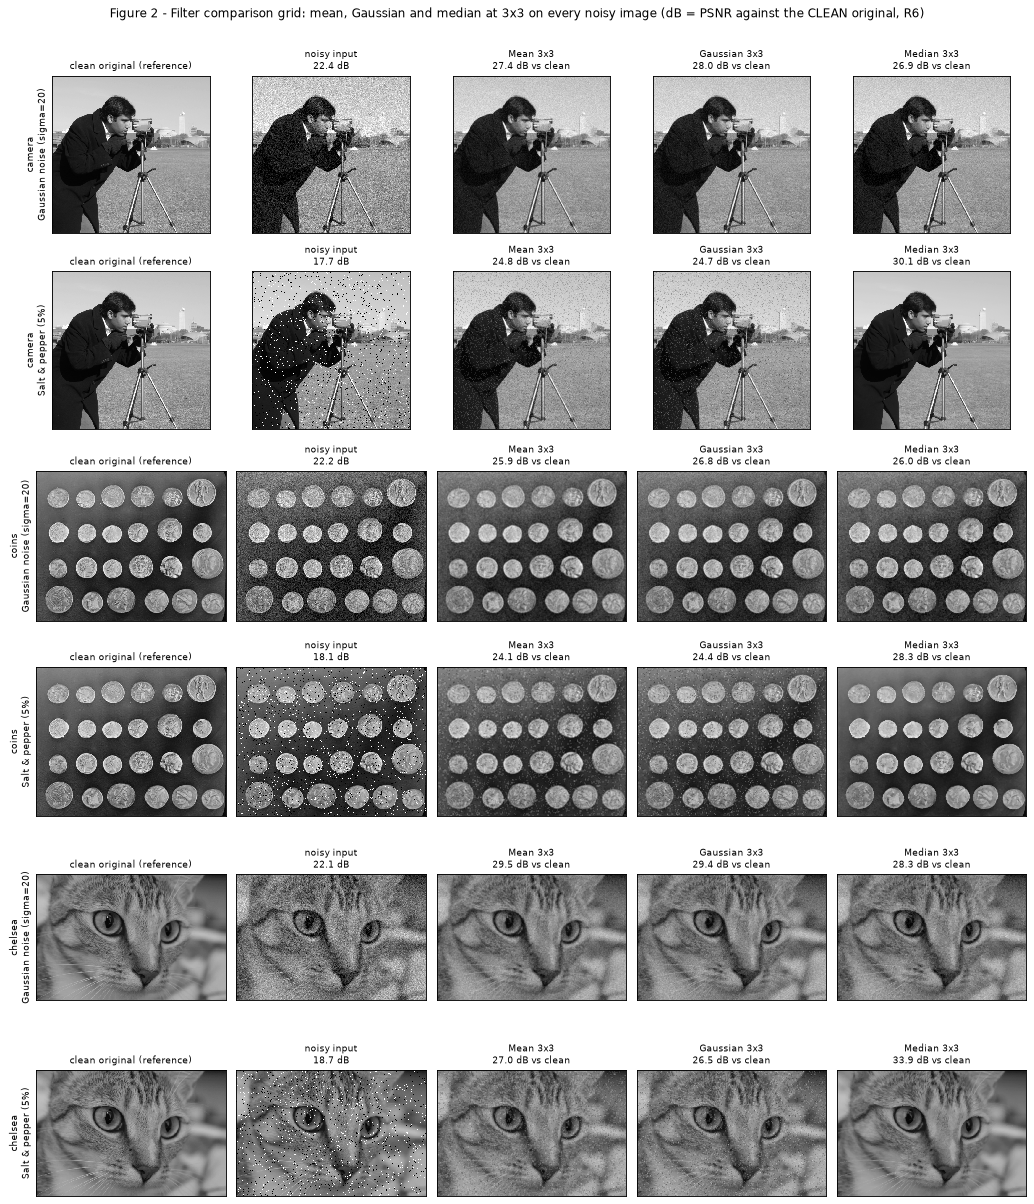

In [17]:
# ---- Figure 2: mean | Gaussian | median (3x3) on every noisy image ----
fig, axes = plt.subplots(6, 5, figsize=(13, 15.5))
r = 0
for name in ORIGINALS:
    for noise in ("gaussian", "saltpepper"):
        noisy_img = NOISY[(name, noise)]
        show(axes[r, 0], ORIGINALS[name], "clean original (reference)")
        show(axes[r, 1], noisy_img, f"noisy input\n{NOISY_SCORE[(name, noise)][1]:.1f} dB")
        for c, fname in enumerate(FILTERS, start=2):
            show(axes[r, c], RESULTS[(name, noise, fname, 3)], f"{fname} 3x3\n{SCORES[(name, noise, fname, 3)][1]:.1f} dB vs clean")
        axes[r, 0].set_ylabel(f"{name}\n{NOISE_LABEL[noise]}", fontsize=8)
        r += 1
fig.suptitle("Figure 2 - Filter comparison grid: mean, Gaussian and median at 3x3 on every noisy image "
             "(dB = PSNR against the CLEAN original, R6)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()

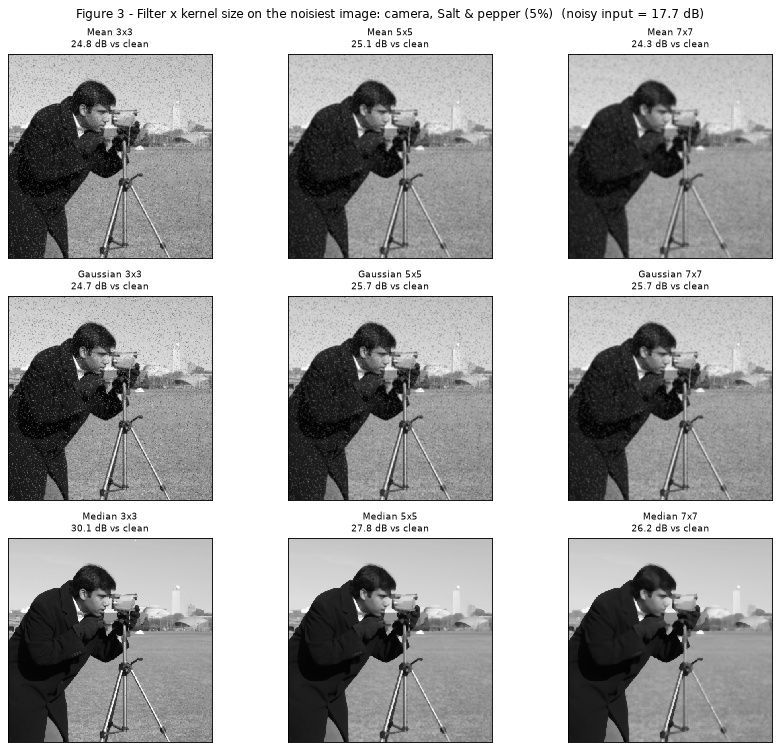

In [18]:
# ---- Figure 3: filter x kernel size on the noisiest image ----
nm, nz = NOISIEST
fig, axes = plt.subplots(3, 3, figsize=(11, 9.5))
for r, fname in enumerate(FILTERS):
    for c, k in enumerate(SIZES):
        show(axes[r, c], RESULTS[(nm, nz, fname, k)], f"{fname} {k}x{k}\n{SCORES[(nm, nz, fname, k)][1]:.1f} dB vs clean")
fig.suptitle(f"Figure 3 - Filter x kernel size on the noisiest image: {nm}, {NOISE_LABEL[nz]}  "
             f"(noisy input = {NOISY_SCORE[NOISIEST][1]:.1f} dB)", fontsize=11)
plt.tight_layout()
plt.show()

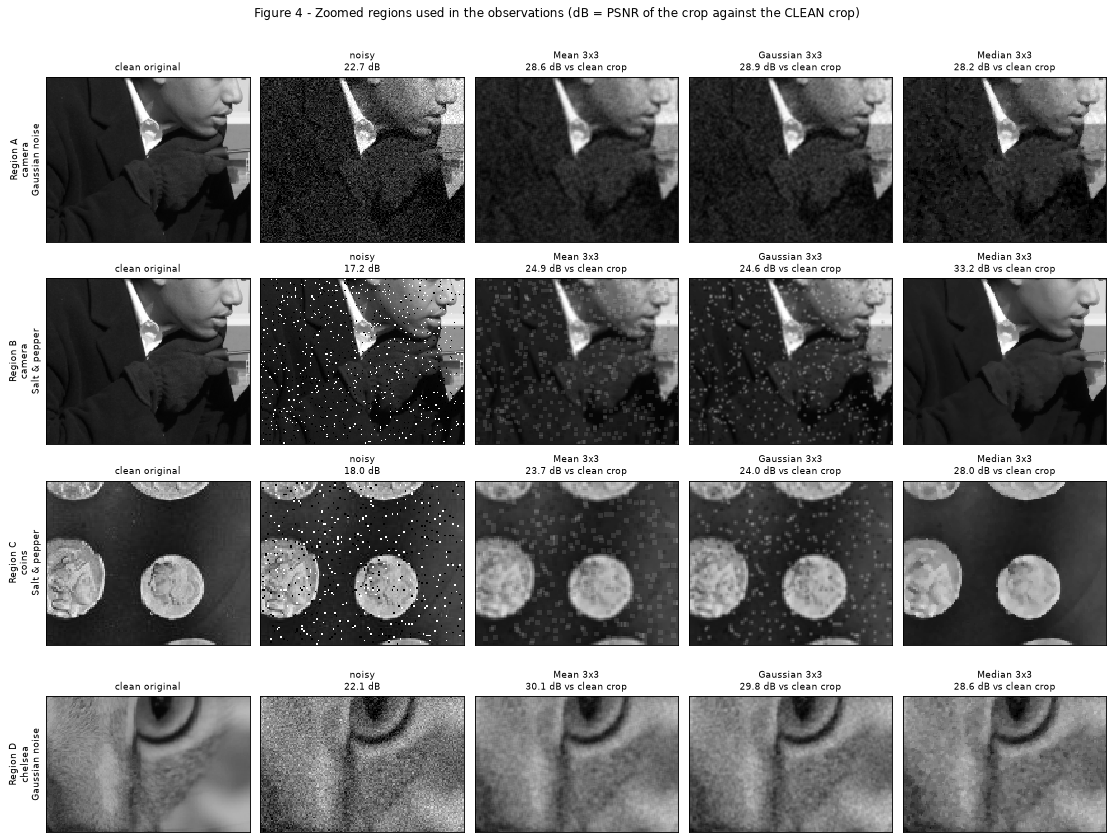

In [19]:
# ---- Figure 4: zoomed regions, 3x3 filters. Region scores are against the CLEAN crop (R6) ----
REGIONS = {   # name: (label, image, noise, (row0, row1, col0, col1))
    "A": ("camera - white collar, chin and dark coat", "camera",  "gaussian",   (150, 280, 100, 260)),
    "B": ("camera - white collar, chin and dark coat", "camera",  "saltpepper", (150, 280, 100, 260)),
    "C": ("coins - rims of several coins on the dark background", "coins", "saltpepper", (60, 160, 260, 384)),
    "D": ("chelsea - eye and fur next to it", "chelsea", "gaussian",   (130, 230, 230, 380)),
}

def crop_psnr(name, test, box):
    y0, y1, x0, x1 = box
    clean = ORIGINALS[name][y0:y1, x0:x1]                        # R6: clean crop is the reference
    return float(peak_signal_noise_ratio(clean, test[y0:y1, x0:x1], data_range=255))

fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for r, (tag, (label, name, noise, box)) in enumerate(REGIONS.items()):
    y0, y1, x0, x1 = box
    show(axes[r, 0], ORIGINALS[name][y0:y1, x0:x1], "clean original")
    show(axes[r, 1], NOISY[(name, noise)][y0:y1, x0:x1], f"noisy\n{crop_psnr(name, NOISY[(name, noise)], box):.1f} dB")
    for c, fname in enumerate(FILTERS, start=2):
        out = RESULTS[(name, noise, fname, 3)]
        show(axes[r, c], out[y0:y1, x0:x1], f"{fname} 3x3\n{crop_psnr(name, out, box):.1f} dB vs clean crop")
    axes[r, 0].set_ylabel(f"Region {tag}\n{name}\n{NOISE_LABEL[noise].split(' (')[0]}", fontsize=8)
fig.suptitle("Figure 4 - Zoomed regions used in the observations (dB = PSNR of the crop against the CLEAN crop)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

coins, row 128: dark background ~ 33, coin rim up to 226
steepest one-pixel jump in the clean original: 150 grey levels

Edge sharpness kept after filtering the CLEAN image (steepest jump / clean steepest jump):
  Mean 3x3        : steepest jump =  60.0 levels  ->    40 % of the original edge steepness
  Gaussian 3x3    : steepest jump =  74.0 levels  ->    49 % of the original edge steepness
  Mean 7x7        : steepest jump =  24.0 levels  ->    16 % of the original edge steepness
  Gaussian 7x7    : steepest jump =  43.0 levels  ->    29 % of the original edge steepness

Grey levels at columns 313-320 of row 128 (the true edge is between columns 316 and 318):
column           313   314   315   316   317   318   319   320
clean original    30    40    33    28    76   226   185   192
Mean 7x7          34    42    66    88   110   133   155   177
Gaussian 7x7      35    36    45    69   108   151   178   189


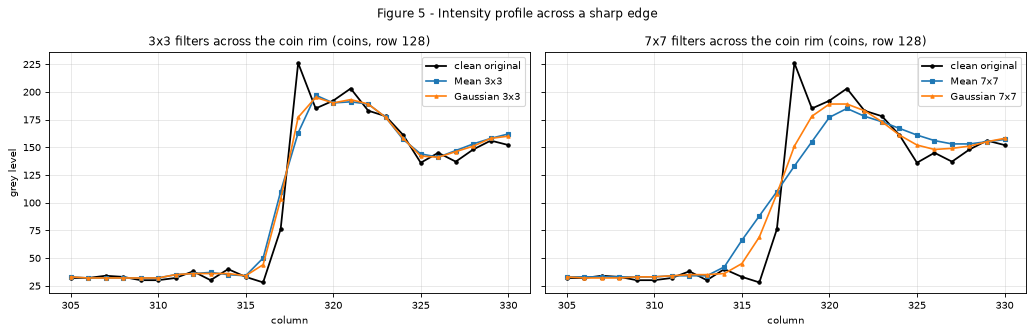

In [20]:
# ---- Figure 5: a sharp edge, filtered WITHOUT noise so only the blurring is visible ----
# Row 128 of 'coins' crosses a coin rim: the grey level jumps from about 30 to about 226 within two pixels.
row, c0, c1 = 128, 305, 331
clean_row = ORIGINALS["coins"][row, c0:c1].astype(np.float64)
xs = np.arange(c0, c1)

def steepest_step(profile):
    # largest grey-level jump between two neighbouring pixels: the sharper the edge, the bigger it is
    return float(np.max(np.abs(np.diff(profile))))

edge_profiles = {"clean original": clean_row}
for k in (3, 7):
    edge_profiles[f"Mean {k}x{k}"]     = mean_cv(ORIGINALS["coins"], k)[row, c0:c1].astype(np.float64)
    edge_profiles[f"Gaussian {k}x{k}"] = gaussian_cv(ORIGINALS["coins"], k)[row, c0:c1].astype(np.float64)

ref_step = steepest_step(clean_row)
print(f"coins, row {row}: dark background ~ {clean_row[:8].mean():.0f}, coin rim up to {clean_row.max():.0f}")
print(f"steepest one-pixel jump in the clean original: {ref_step:.0f} grey levels\n")
print("Edge sharpness kept after filtering the CLEAN image (steepest jump / clean steepest jump):")
for label, prof in edge_profiles.items():
    if label != "clean original":
        print(f"  {label:16s}: steepest jump = {steepest_step(prof):5.1f} levels  ->  {100 * steepest_step(prof) / ref_step:4.0f} % of the original edge steepness")

print(f"\nGrey levels at columns 313-320 of row {row} (the true edge is between columns 316 and 318):")
print("column         " + " ".join(f"{c:5d}" for c in range(313, 321)))
for label in ("clean original", "Mean 7x7", "Gaussian 7x7"):
    print(f"{label:14s} " + " ".join(f"{v:5.0f}" for v in edge_profiles[label][313 - c0: 321 - c0]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, k in zip(ax, (3, 7)):
    a.plot(xs, clean_row, "k-o", ms=3, lw=1.6, label="clean original")
    a.plot(xs, edge_profiles[f"Mean {k}x{k}"],     "-s", ms=3, label=f"Mean {k}x{k}")
    a.plot(xs, edge_profiles[f"Gaussian {k}x{k}"], "-^", ms=3, label=f"Gaussian {k}x{k}")
    a.set_title(f"{k}x{k} filters across the coin rim (coins, row {row})")
    a.set_xlabel("column"); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel("grey level")
fig.suptitle("Figure 5 - Intensity profile across a sharp edge", fontsize=11)
plt.tight_layout()
plt.show()

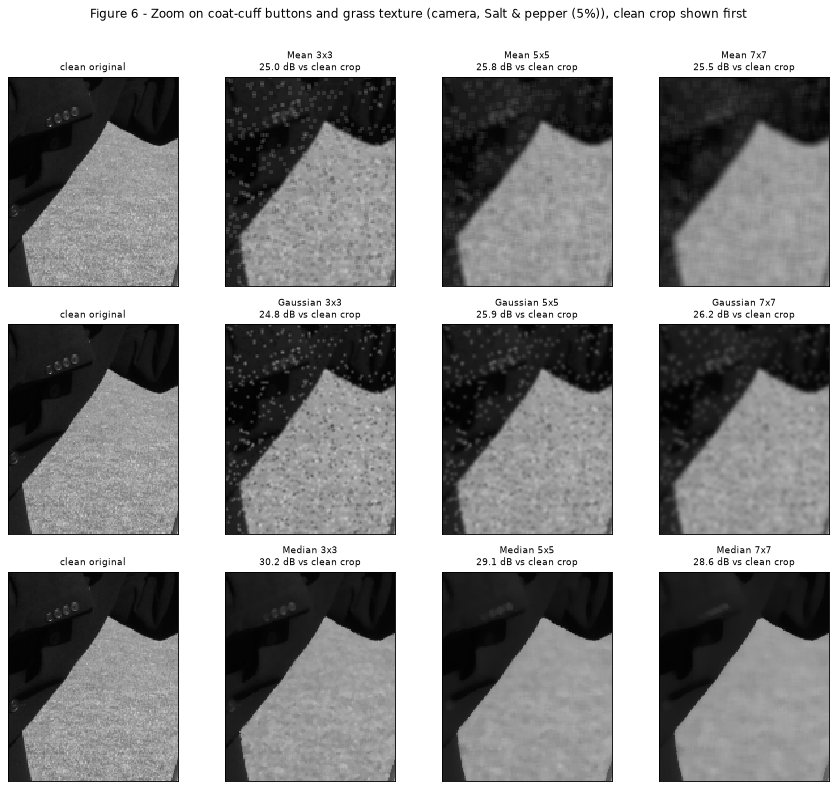

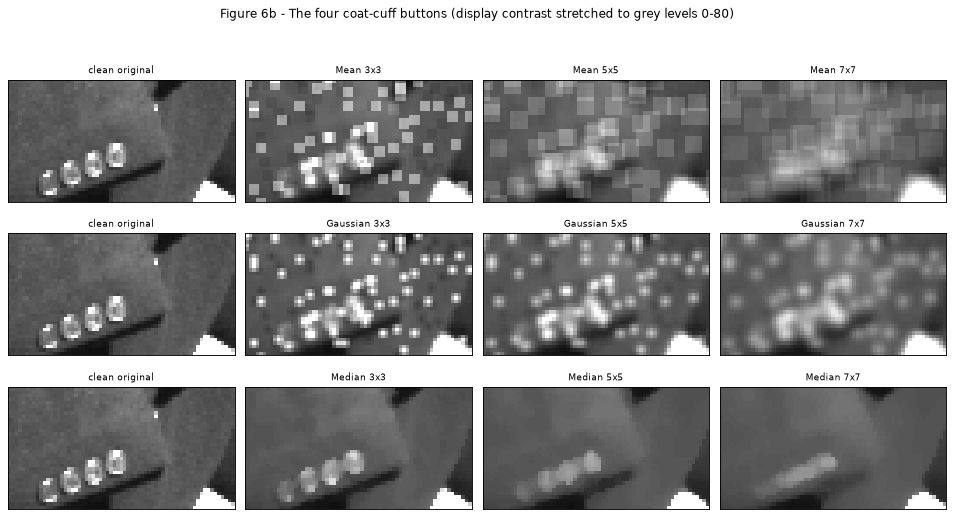

In [21]:
# ---- Figure 6: what a bigger kernel does to fine detail (noisiest image, zoom on the coat cuff and grass) ----
nm, nz = NOISIEST
y0, y1, x0, x1 = 260, 420, 130, 260
fig, axes = plt.subplots(3, 4, figsize=(11, 10))
for r, fname in enumerate(FILTERS):
    show(axes[r, 0], ORIGINALS[nm][y0:y1, x0:x1], "clean original")
    for c, k in enumerate(SIZES, start=1):
        out = RESULTS[(nm, nz, fname, k)]
        show(axes[r, c], out[y0:y1, x0:x1], f"{fname} {k}x{k}\n{crop_psnr(nm, out, (y0, y1, x0, x1)):.1f} dB vs clean crop")
fig.suptitle(f"Figure 6 - Zoom on coat-cuff buttons and grass texture ({nm}, {NOISE_LABEL[nz]}), clean crop shown first", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# ---- Figure 6b: the four buttons only, display contrast stretched (grey levels 0-80 -> black-white) because the cuff is very dark.
# Only the DISPLAY is stretched; the pixel values being shown are exactly the filter outputs.
by0, by1, bx0, bx1 = 265, 300, 150, 215
fig, axes = plt.subplots(3, 4, figsize=(12, 6.8))
for r, fname in enumerate(FILTERS):
    axes[r, 0].imshow(ORIGINALS[nm][by0:by1, bx0:bx1], cmap="gray", vmin=0, vmax=80, interpolation="nearest")
    axes[r, 0].set_title("clean original", fontsize=8)
    for c, k in enumerate(SIZES, start=1):
        axes[r, c].imshow(RESULTS[(nm, nz, fname, k)][by0:by1, bx0:bx1], cmap="gray", vmin=0, vmax=80, interpolation="nearest")
        axes[r, c].set_title(f"{fname} {k}x{k}", fontsize=8)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Figure 6b - The four coat-cuff buttons (display contrast stretched to grey levels 0-80)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Position of the step edge after a 1-D mean filter of width k (true position = 11.5):
  k = 3 (odd ): edge at 11.50   shift = +0.00 px
  k = 4 (even): edge at 12.00   shift = +0.50 px
  k = 5 (odd ): edge at 11.50   shift = +0.00 px
  k = 6 (even): edge at 12.00   shift = +0.50 px


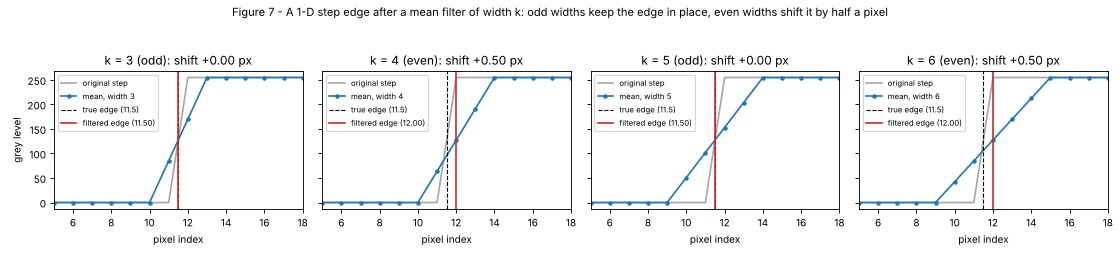

In [22]:
# ---- Why odd? An even kernel has no centre pixel, so the output lands half a pixel off ----
step = np.r_[np.zeros(12), np.full(12, 255.0)]            # ideal edge between index 11 and 12 (position 11.5)

def edge_position(profile):
    d = np.diff(profile)[6:-6]                           # ignore the ends of the signal
    idx = np.arange(len(np.diff(profile)))[6:-6]
    return float((idx * d).sum() / d.sum() + 0.5)        # centre of mass of the gradient

print("Position of the step edge after a 1-D mean filter of width k (true position = 11.5):")
for k in (3, 4, 5, 6):
    out = np.convolve(step, np.full(k, 1.0 / k), mode="same")
    pos = edge_position(out)
    print(f"  k = {k} ({'odd ' if k % 2 else 'even'}): edge at {pos:5.2f}   shift = {pos - 11.5:+.2f} px")

# ---- Figure 7: the same 1-D test drawn, so the answer to Observation 5 can point to a figure ----
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
xs7 = np.arange(len(step))
for ax, k in zip(axes, (3, 4, 5, 6)):
    out = np.convolve(step, np.full(k, 1.0 / k), mode="same")
    pos = edge_position(out)
    ax.plot(xs7, step, color="0.65", lw=1.5, label="original step")
    ax.plot(xs7, out, "o-", color="tab:blue", ms=3, label=f"mean, width {k}")
    ax.axvline(11.5, color="k", ls="--", lw=1, label="true edge (11.5)")
    ax.axvline(pos, color="tab:red", lw=1.5, label=f"filtered edge ({pos:.2f})")
    ax.set_xlim(5, 18)
    ax.set_title(f"k = {k} ({'odd' if k % 2 else 'even'}): shift {pos - 11.5:+.2f} px")
    ax.set_xlabel("pixel index")
    ax.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("grey level")
fig.suptitle("Figure 7 - A 1-D step edge after a mean filter of width k: odd widths keep the edge in place, even widths shift it by half a pixel", fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## 7. Observations and comparisons

All numbers below are read from the tables and figures above. Every dB value is a PSNR measured **against the clean original** (R6). Where a *region* is mentioned, its dB value compares that crop with the same crop of the clean image. Numbers come from the run recorded in this notebook (Python 3.14.6, NumPy 2.5, OpenCV 5.0, scikit-image 0.26).

**1. Which filter looks best on Gaussian noise, and which looks worst?**

- **Best: the Gaussian filter.** Over the three images at 3×3 it has the highest average PSNR against the clean originals, **28.08 dB**, against 27.59 dB for the mean and 27.06 dB for the median (the noisy inputs average 22.24 dB). It wins on `camera` (27.99 vs 27.37 and 26.93 dB) and on `coins` (26.79 vs 25.86 and 25.98 dB), and is within 0.1 dB of the mean on `chelsea` (29.45 vs 29.54 dB). In **Figure 4, region A** (white collar and dark coat of the cameraman) it scores 28.9 dB against 28.6 dB for the mean.
- **Worst: the median.** It has the lowest SSIM on all three images (for example `camera` 0.573 against 0.639 for the mean and 0.644 for the Gaussian). It also has the lowest PSNR on `camera` and `chelsea` and on average; only on `coins` is the mean 0.1 dB lower. In **Figure 4, region A** the dark coat in the median column stays mottled with grey blotches, and in **region D** the fur beside the cat's eye looks patchy (28.6 dB, against 30.1 dB for the mean). Every pixel here carries a little noise, so the middle of nine slightly wrong values is still slightly wrong, and nothing is averaged away.
- All three still help a lot (+4.8 to +5.8 dB), so the gaps between them are small next to the gain from filtering at all.

**2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**

- **Best: the median, by a wide margin.** Average PSNR is **30.76 dB** against 25.30 dB (mean) and 25.20 dB (Gaussian), and it is best on every image: `camera` 30.08, `coins` 28.33, `chelsea` 33.86 dB. In **Figure 4, region B** (cameraman's collar and coat) all the white and black dots are gone in the median column (33.2 dB), while the mean and Gaussian columns (24.9 and 24.6 dB) still show scattered grey squares on the dark coat. In **region C** (the dark background between the coins) the median column is clean, while the mean and Gaussian columns show faint grey 3×3 squares at every place a dot used to be.
- **Why mean and Gaussian fail:** they are weighted sums, so an outlier of 255 or 0 is not rejected: it is blended in, and it contaminates *every* output whose window contains it. That is why one dot becomes a 3×3 grey square (the squares in region C). Dry-run Exercise 1 shows the size of the damage: a single 255 among 40s becomes 64 with the mean and 94 with the Gaussian (+24 and +54), because the Gaussian gives the centre pixel 4/16 of the weight. The median sorts the window, the spike lands at the end of the list, and the output is 40. A spike can only win if at least 5 of the 9 pixels in the window are corrupted, which at 5 % noise almost never happens. Larger kernels (**Figure 3**, top two rows) only spread each spike into a bigger, fainter blotch.

**3. How do mean and Gaussian compare on a sharp edge?**

- **Figure 5** filters the *clean* `coins` image across a coin rim (row 128, columns 316 to 318, where the grey level jumps 28 → 76 → 226), so only blurring is measured. The Gaussian keeps more of the edge: after 3×3 the steepest one-pixel jump is **49 %** of the original for the Gaussian and **40 %** for the mean. After 7×7 it is **29 %** against **16 %**.
- In the 7×7 panel the mean is already at 66 and 88 in columns 315 and 316, where the clean image is still at 33 and 28, so it has started climbing two to three pixels before the real edge. The Gaussian is at 45 and 69 at the same columns and follows the clean curve more closely.
- The reason is the weights. A 7×7 mean gives every pixel 1/49 (2.0 %), including pixels at the far side of an edge. The 7×7 Gaussian gives the centre 1296/16384 (7.9 %) and the corners only 16/16384 (0.1 %), so far-away pixels hardly mix in. At 3×3 the difference is modest (the curves in the left panel nearly overlap); it grows with kernel size.

**4. What happens to fine detail at 7×7?**

- **Figure 6** zooms into the noisiest image (`camera` with salt-and-pepper noise). In the clean crop, four small buttons are visible on the coat cuff at the top left, and the grass has a fine grainy texture. **Figure 6b** shows just the buttons with the display contrast stretched (only the display, not the pixel values), because the cuff is very dark.
- Only **Median 3×3** keeps the four buttons clearly separate. In the mean and Gaussian rows they are already blurred together at 5×5, and **at 7×7 all three rows show only one faint smeared streak** with no individual button left. The grass in **Figure 6** has flattened into a uniform grey patch at 7×7, where the 3×3 outputs still show some grain.
- The three filters lose detail differently. The mean 7×7 also smears the boundary between the coat and the grass into a soft band. The median 7×7 keeps that boundary crisp but rounds it into a stair-stepped, cartoon-like shape.
- **Warning about PSNR:** Gaussian 7×7 scores *higher* than Gaussian 3×3 in this crop (26.2 vs 24.8 dB), simply because it dilutes more of the salt-and-pepper specks, even though it destroys the buttons. The median goes the other way (30.2 → 28.6 dB from 3×3 to 7×7), because nothing is left to remove and only detail is lost. The figure has to be read together with the number.

**5. Why must the kernel size be odd?**

- An odd kernel has one centre pixel, and the output is written back to exactly that pixel. In Dry-run Exercise 1 the 255 spike sits in the middle of the 3×3 window, and the result belongs to that pixel. An even kernel has no single centre pixel, so the result falls half a pixel between two pixels.
- **Figure 7** (the 1-D test at the end of Section 6) shows this: a step edge at position 11.5 stays at **11.50** after a 3-wide or 5-wide mean (panels 1 and 3, red line on the dashed line), but moves to **12.00** (a **+0.5 px shift**) after a 4-wide or 6-wide mean (panels 2 and 4, red line half a pixel to the right of the dashed line). The even kernel still gives an output of the right size, so R1 is not the problem. The problem is that there is no single pixel to write the result back to, so the whole picture is shifted by half a pixel.
- A median needs one middle value. A 3×3, 5×5 or 7×7 window has 9, 25 or 49 values, which is an odd count, so there is a true middle. A 4×4 window has 16 values and no single middle. This is why `cv2.medianBlur(img, 4)` raises an error (Section 2.1, R4).

## 8. Viva preparation

The lab asks for any two answers. Brief answers to all six are given here.

**What is a kernel?** A small matrix of weights (here 3×3, 5×5 or 7×7). It is slid over the image, and each output pixel is the weighted sum of the neighbourhood under it. The weights decide what the filter does: equal weights blur uniformly, bell-shaped weights blur gently, and weights with positive and negative parts detect edges.

**Apply a 3×3 mean kernel to a window given on the spot.** Add the nine values, divide by 9, round. With the window from Exercise 1: (8 × 40 + 255) ÷ 9 = 575 ÷ 9 = 63.9, which rounds to 64.

**Why does the median remove a 255 spike but the mean does not?** The mean gives every pixel in the window the same weight, so the spike adds (255 − 40) ÷ 9 ≈ 24 levels to the result. The median sorts the nine values and takes the 5th. The spike is the largest, so it sits at the end of the list and cannot be the middle unless at least 5 of the 9 pixels are corrupted. In Exercise 1: mean 64, median 40.

**Why do the Gaussian weights sum to 16, and why divide by it?** The 3×3 kernel is the outer product of [1, 2, 1] with itself, so its weights are 1 + 2 + 1 + 2 + 4 + 2 + 1 + 2 + 1 = 16. Dividing by 16 makes them sum to 1 (R3), so a flat region keeps its brightness: a flat patch of 100s gives 1600 ÷ 16 = 100. Without the division, every output would be 16 times brighter and mostly clipped to 255.

**Why do we pad the border before filtering?** Border pixels do not have a full neighbourhood: the window hangs off the image. Padding supplies the missing pixels, so the output keeps the same size as the input (R1). Reflect padding is used because it keeps the local statistics. In Exercise 2 it gives 36.7 at the corner, while zero padding would give 13.3 and darken the border.

**Which filter for salt-and-pepper noise, and why?** The median, because it ignores outliers instead of averaging them in. It gave 30.76 dB on average, against about 25.3 dB for the mean and the Gaussian (Figure 4, regions B and C).

## 9. Final compliance summary

This cell re-checks every rule from the lab with fresh computations (not stored results) and also confirms that the original images were never changed.

In [23]:
checks = []

# R1: same size as the input, reflect borders (median border behaviour verified against the definition in Section 2)
r1 = all(o.shape == NOISY[(k[0], k[1])].shape for k, o in RESULTS.items())
r1 &= conv2d_loop(ORIGINALS["coins"][:30, :30], mean_kernel(3)).shape == (30, 30)
checks.append(("R1", "every filter returns the input size; borders use reflect padding", r1))

# R2: float64 calculation, uint8 only at the end with round + clip
r2 = all(o.dtype == np.uint8 and o.min() >= 0 and o.max() <= 255 for o in RESULTS.values())
r2 &= conv2d_loop(ORIGINALS["coins"][:30, :30], mean_kernel(3)).dtype == np.float64
r2 &= int(to_uint8(np.array([-5.2, 127.5, 300.0])).tolist() == [0, 128, 255])
checks.append(("R2", "float64 inside, uint8 (round + clip, 0-255) at the end", r2))

# R3: smoothing kernels sum to 1
r3 = all(np.isclose(m(k).sum(), 1.0) for m in (mean_kernel, gaussian_kernel) for k in ALLOWED_SIZES)
checks.append(("R3", "all six smoothing kernels sum to 1", r3))

# R4: even sizes rejected
def rejects(fn):
    try: fn(); return False
    except (ValueError, cv2.error): return True
r4 = all(rejects(lambda k=k: median_cv(ORIGINALS["camera"], k)) for k in (2, 4, 6)) and rejects(lambda: cv2.medianBlur(ORIGINALS["camera"], 4))
checks.append(("R4", "kernel sizes are odd (3, 5, 7); even sizes raise an error", r4))

# R5: seed=5 reproduces identical noisy images
again = build_noisy()
r5 = all(np.array_equal(NOISY[k], again[k]) for k in NOISY)
checks.append(("R5", "seed=5 reproduces identical noisy images", r5))

# R6: every score recomputed directly against the CLEAN original
r6 = all(np.isclose(SCORES[k][1], peak_signal_noise_ratio(ORIGINALS[k[0]], RESULTS[k], data_range=255)) for k in RESULTS)
checks.append(("R6", "all 54 filtered images were scored against the clean original", r6))

# originals untouched
untouched = all(sha(ORIGINALS[n]) == ORIG_FINGERPRINT[n] for n in ORIGINALS)
checks.append(("---", "the three original test images are unchanged since loading", untouched))

for tag, text, ok in checks:
    print(f"{tag:4s} {'PASS' if ok else 'FAIL'}  {text}")
assert all(ok for _, _, ok in checks)
print("\nAll checks passed.")

R1   PASS  every filter returns the input size; borders use reflect padding
R2   PASS  float64 inside, uint8 (round + clip, 0-255) at the end
R3   PASS  all six smoothing kernels sum to 1
R4   PASS  kernel sizes are odd (3, 5, 7); even sizes raise an error
R5   PASS  seed=5 reproduces identical noisy images
R6   PASS  all 54 filtered images were scored against the clean original
---  PASS  the three original test images are unchanged since loading

All checks passed.


## Summary

- `conv2d_loop` flips the kernel, reflect-pads, calculates in `float64` and returns the input size. It matches `cv2.filter2D` exactly (max difference 0.0) on an asymmetric kernel, and the mean (0 levels off) and Gaussian (at most 1 level off) match `cv2.blur` and `cv2.GaussianBlur`.
- Both dry-run exercises were calculated by hand and match the code: Exercise 1 gives mean 64, Gaussian 94, median 40, and Exercise 2 gives 37.
- On Gaussian noise the Gaussian filter scored best and the median worst. On salt-and-pepper noise the median was far ahead of the other two.
- `cv2.medianBlur` always replicates the border. It was wrapped with reflect padding so that R1 also holds for the median.